### **Name**: Mohammed Feras Sawab
---
### **ID**: 2240009066
---

# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset_Download.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

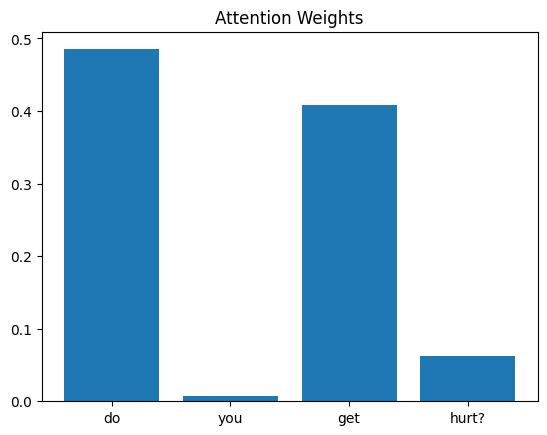

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

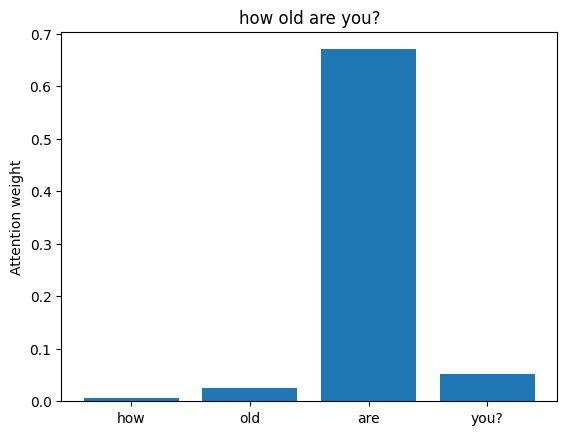

Question: how old are you?
Weights: {'how': 0.007, 'old': 0.025, 'are': 0.67, 'you?': 0.052}
Highest attention: are
Predicted answer: People created me.
Correct answer: Age doesn't really apply to me.



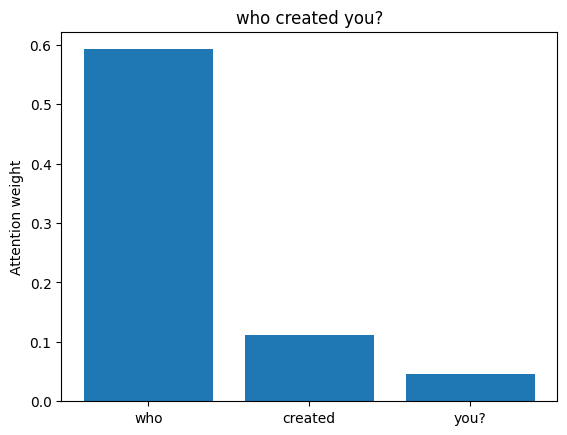

Question: who created you?
Weights: {'who': 0.592, 'created': 0.112, 'you?': 0.046}
Highest attention: who
Predicted answer: People created me.
Correct answer: People created me.



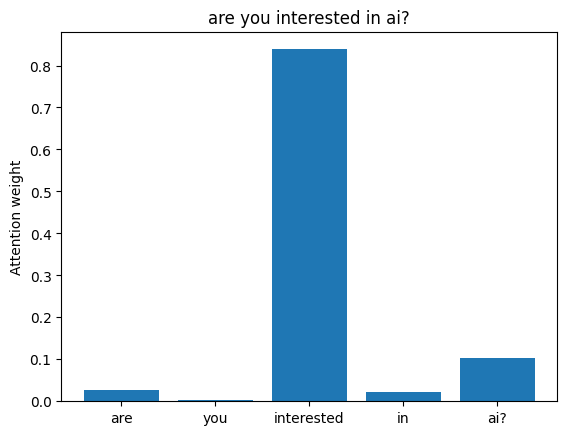

Question: are you interested in ai?
Weights: {'are': 0.026, 'you': 0.002, 'interested': 0.839, 'in': 0.022, 'ai?': 0.102}
Highest attention: interested
Predicted answer: Not at all.
Correct answer: The world of technology is fascinating.



In [7]:
def show_attention(i):
    question = df["question"][i]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    word_weights = weights[0, :len(words)].tolist()
    top_word = words[word_weights.index(max(word_weights))]

    plt.bar(words, word_weights)
    plt.title(question)
    plt.ylabel("Attention weight")
    plt.show()

    print("Question:", question)
    print("Weights:", {w: round(v, 3) for w, v in zip(words, word_weights)})
    print("Highest attention:", top_word)
    print("Predicted answer:", df[df["answer_id"] == prediction.argmax(1).item()]["answer"].iloc[0])
    print("Correct answer:", df["answer"][i])
    print()
    return top_word

# Three questions from three different answer groups
for i in [24, 48, 130]:
    show_attention(i)


**Answer:**

| Question | Word with the highest attention | Weight |
|---|---|---|
| how old are you? | are | 0.670 |
| who created you? | who | 0.592 |
| are you interested in ai? | interested | 0.839 |

Only partly. "who" and "interested" do help to understand their questions: "who" shows that the question asks about a person, and "interested" is the main idea of the third question. But in "how old are you?" the model focuses on "are", which is a common word with little meaning, and gives only 0.025 to "old", the word that really shows the question is about age.

The model also predicted the correct answer for only one of the three questions ("who created you?"). So high attention shows which word the model used the most, not which word is the most important to a person, and it does not guarantee a correct answer.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Word that gets the most attention in each question:



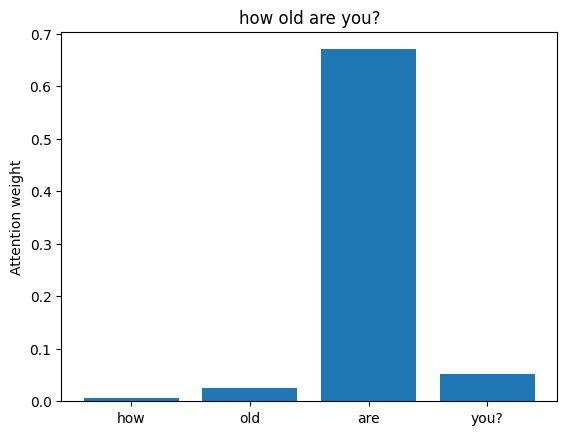

Question: how old are you?
Weights: {'how': 0.007, 'old': 0.025, 'are': 0.67, 'you?': 0.052}
Highest attention: are
Predicted answer: People created me.
Correct answer: Age doesn't really apply to me.



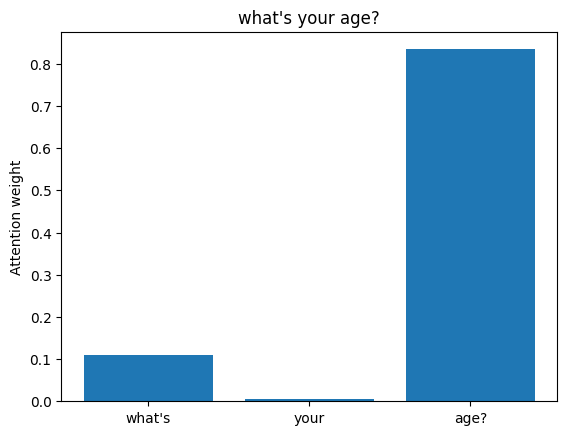

Question: what's your age?
Weights: {"what's": 0.109, 'your': 0.005, 'age?': 0.834}
Highest attention: age?
Predicted answer: Not at all.
Correct answer: Age doesn't really apply to me.

'how old are you?' -> 'are'
"what's your age?" -> 'age?'


In [8]:
# Same meaning (asking for the age), different wording
q1 = df.index[df["question"] == "how old are you?"][0]
q2 = df.index[df["question"] == "what's your age?"][0]

print("Word that gets the most attention in each question:\n")
top1 = show_attention(q1)
top2 = show_attention(q2)
print(f"{df['question'][q1]!r} -> {top1!r}")
print(f"{df['question'][q2]!r} -> {top2!r}")


**Answer:**

I compared "how old are you?" and "what's your age?". Both ask for the age and belong to the same answer group.

| Question | Word with the highest attention | Weight |
|---|---|---|
| how old are you? | are | 0.670 |
| what's your age? | age | 0.834 |

The model focuses on different words. In the second question it focuses on "age", the word that carries the meaning, but in the first question it focuses on "are" and gives only 0.025 to "old". It also predicted a wrong answer for both questions ("People created me." and "Not at all.").

This suggests that attention does not understand meaning by itself. It gives weights based on the words the model sees and what it learned during training, so two questions with the same meaning can get different attention if their words are different. The model would need to learn from the training data that "old" and "age" point to the same answer.